# 03 Analytics: star schema, governed KPIs and in-house marketing mix
Layering: **data** (star schema) -> **semantic** (KPI catalog, SQL views, DAX) -> **visualization** (Power BI / PNG).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
FIG = ROOT / "reports" / "figures"
def show(p, w=950): display(Image(filename=str(FIG / p), width=w))

In [2]:
from cx_suite.analytics import star_schema, kpis, mmm
t = star_schema.load()
assert star_schema.validate(t).passed.all()
kpis.catalog_frame()

,tier,kpi,definition,formula,grain,direction,target,owner
0,North Star,Incremental Marketing ROI,Incremental revenue attributed by the MMM per ...,SUM(mmm_incremental_revenue) / SUM(spend_usd),brand x channel x quarter,up,>= 2.0,Performance Optimization
1,North Star,Net Promoter Score (NPS),% promoters (9-10) minus % detractors (0-6) am...,100 * (COUNT(nps>=9) - COUNT(nps<=6)) / COUNT(...,brand x quarter,up,>= 40,Customer Insights
2,Driver,Cost per Order (CPO),Total marketing spend divided by orders,SUM(spend_usd) / SUM(orders),brand x region x quarter,down,brand-specific,Performance Optimization
3,Driver,Revenue per Marketing $,Total (not incremental) revenue per $ spend; d...,SUM(revenue_usd) / SUM(spend_usd),brand x quarter,up,trend,Performance Optimization
4,Driver,New Account Acquisition,Accounts placing a first order in the period,SUM(new_accounts),brand x region x quarter,up,+10% YoY,Commercial Ops
5,Driver,Digital Engagement Rate,Clicks per impression across paid + owned digital,SUM(clicks) / SUM(impressions),channel x quarter,up,>= 1.2%,Digital Analytics
6,Driver,Non-personal Promotion Share,Share of spend in non-personal channels,SUM(spend where promotion_type='Non-personal')...,brand x quarter,context,35-45%,Brand Ops
7,Diagnostic,CSAT Top-2-Box,% of interactions rated 4 or 5 of 5,AVG(csat_1to5 >= 4),touchpoint x quarter,up,>= 75%,Customer Service
8,Diagnostic,First Contact Resolution,% of service interactions resolved on first co...,AVG(first_contact_resolved) WHERE is_service,touchpoint x quarter,up,>= 70%,Customer Service
9,Diagnostic,Avg Resolution Hours,Mean hours from case open to resolution (servi...,AVG(resolution_hrs) WHERE is_service,touchpoint x quarter,down,<= 18 h,Customer Service


## 1. MMM input frame (brand x region x week)

In [3]:
mf = star_schema.model_frame(t)
mf.head()

,brand_code,region_key,date_key,CONF,DISP,EML,REP,SOC,SRCH,WEB,orders,revenue_usd,week_start,is_holiday_week,iso_week
0,BEC_HEM,1,20230102,906.01,0.0,1463.42,8766.76,0.0,2248.10,1831.25,440,209343.89,2023-01-02,1,1
1,BEC_HEM,1,20230109,2256.00,0.0,2410.82,22666.69,0.0,2136.01,930.00,498,237312.01,2023-01-09,0,2
2,BEC_HEM,1,20230116,2590.02,0.0,1561.46,20696.14,0.0,1208.65,991.04,475,219110.76,2023-01-16,0,3
3,BEC_HEM,1,20230123,2341.66,0.0,2019.10,13862.57,0.0,1522.23,566.03,492,238497.74,2023-01-23,0,4
4,BEC_HEM,1,20230130,3666.44,0.0,807.08,19004.71,0.0,1517.43,637.24,516,244446.73,2023-01-30,0,5


## 2. Fit the geo-pooled MMM
Adstock + Hill saturation, MAP estimation with weakly informative ROI priors, lift-test priors for low-spend channels, 13-week hold-out, block-bootstrap intervals.

In [4]:
res = mmm.run(mf)
S = res['summary']
pd.DataFrame({b: {'R2 (national)': S[b]['r2_full'], 'hold-out MAPE': S[b]['mape'],
    'media share of orders': S[b]['media_share_of_orders'], 'reallocation uplift': S[b]['optimizer']['uplift_pct']}
    for b in ['BEC_IA','BEC_HEM','C2N_AD2']}).T.round(3)

[mmm] BEC_IA: R2=0.907 holdout MAPE=1.8% optimizer +4.7% incremental revenue


[mmm] BEC_HEM: R2=0.871 holdout MAPE=2.1% optimizer +4.0% incremental revenue


[mmm] C2N_AD2: R2=0.979 holdout MAPE=4.2% optimizer +6.4% incremental revenue


,R2 (national),hold-out MAPE,media share of orders,reallocation uplift
BEC_IA,0.907,0.018,0.325,0.047
BEC_HEM,0.871,0.021,0.157,0.040
C2N_AD2,0.979,0.042,0.170,0.064


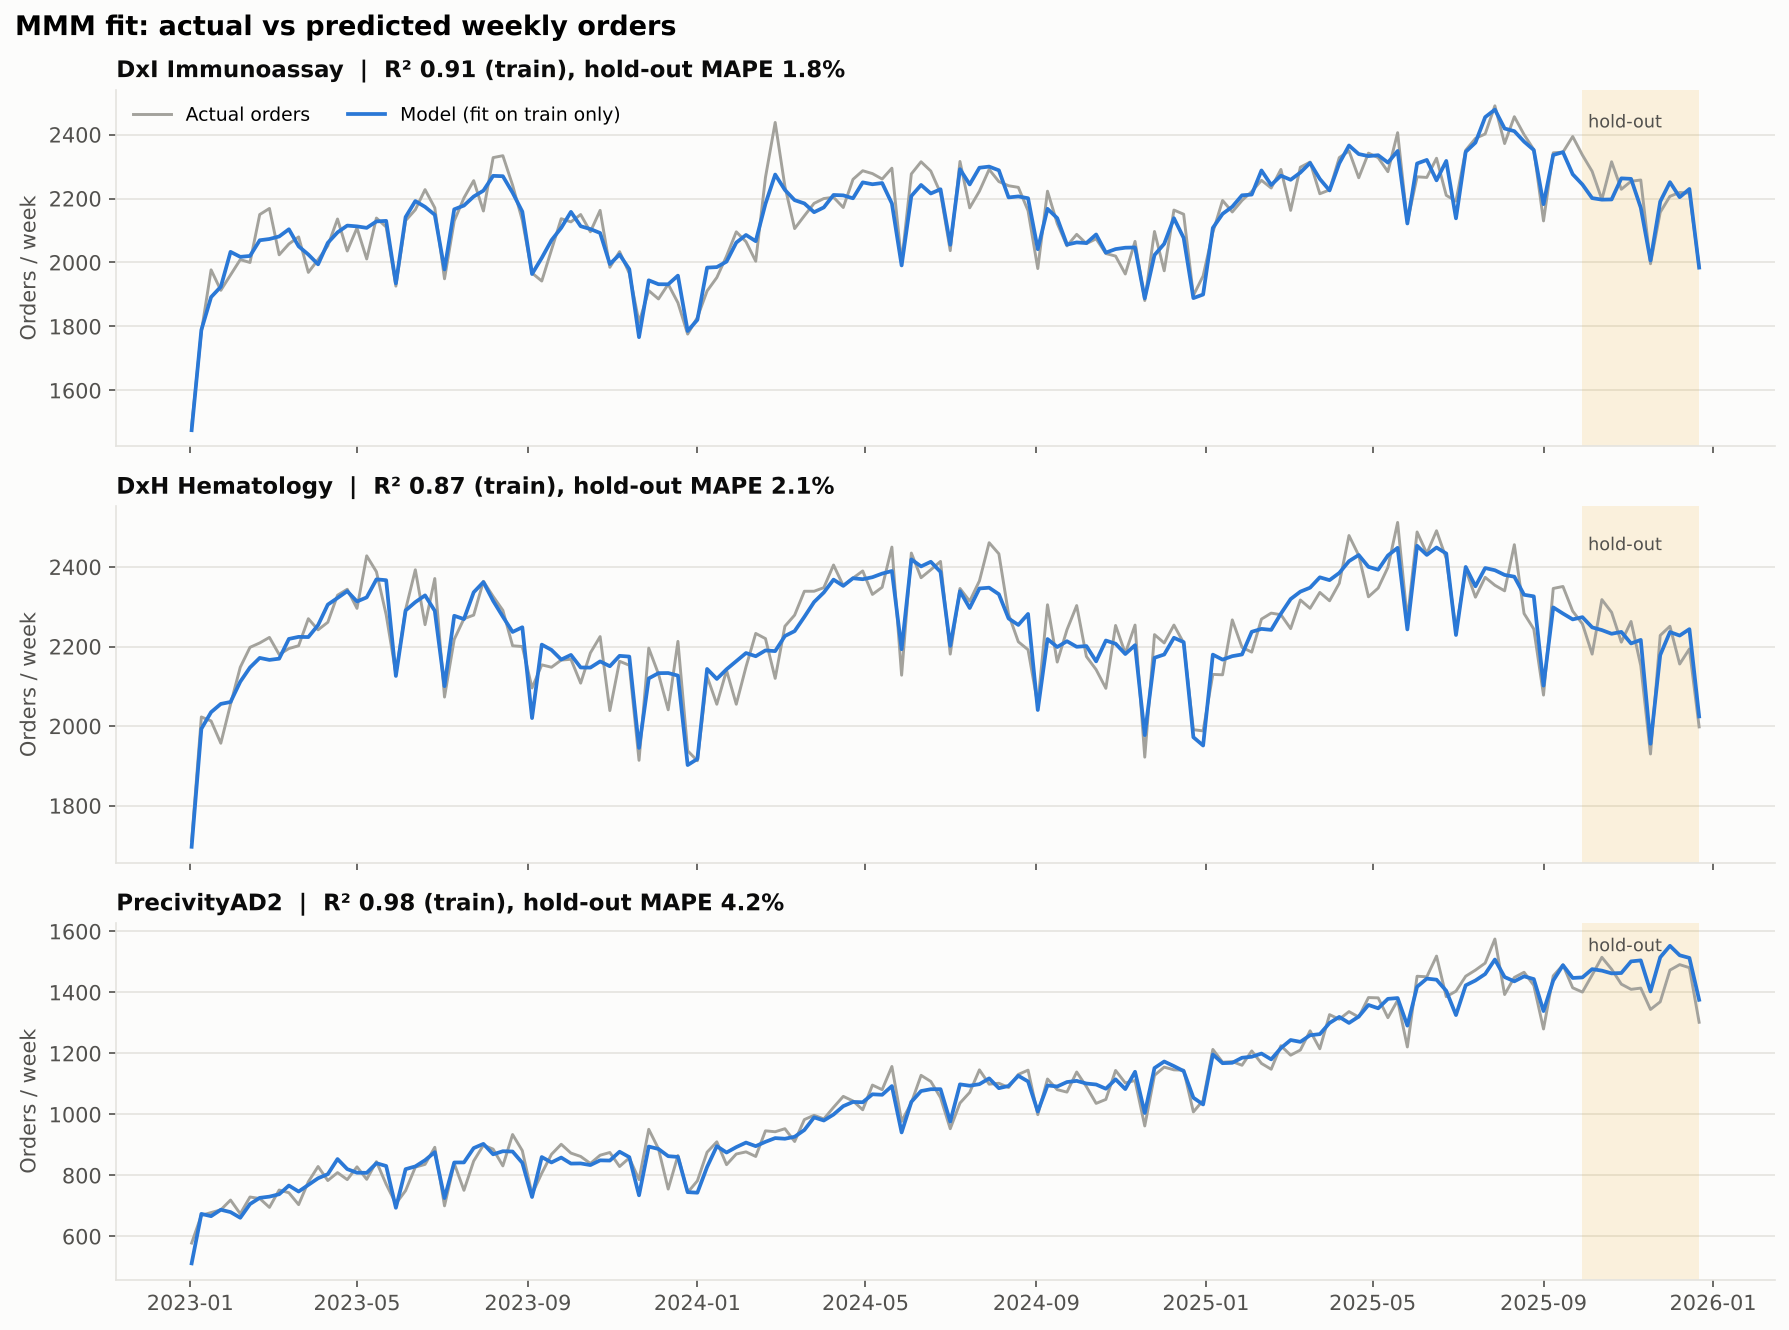

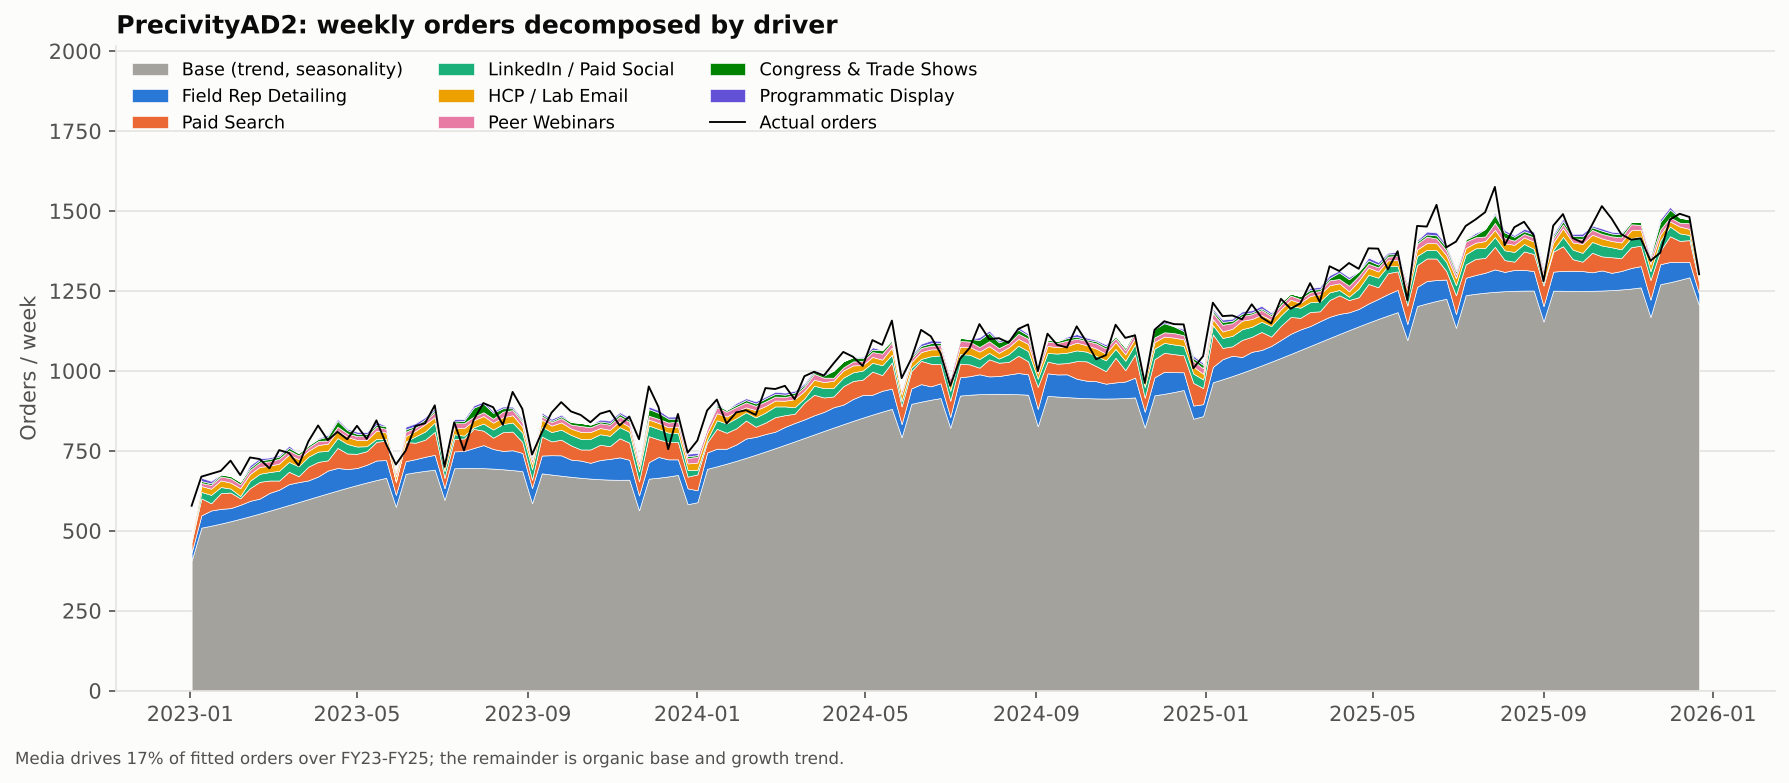

In [5]:
show('analytics/05_mmm_fit_holdout.png'); show('analytics/06_mmm_contribution_decomposition.png')

In [6]:
roi = pd.DataFrame({b: S[b]['roi'] for b in ['BEC_IA','BEC_HEM','C2N_AD2']}).round(2)
truth = pd.DataFrame({b: S[b]['true_roi'] for b in ['BEC_IA','BEC_HEM','C2N_AD2']})
pd.concat({'MMM ROI': roi, 'true ROI': truth}, axis=1)

MMM ROI                 true ROI                
      BEC_IA BEC_HEM C2N_AD2   BEC_IA BEC_HEM C2N_AD2
REP     2.14    1.11    1.51      1.9     1.6     2.4
EML     3.72    3.24    4.81      4.5     3.8     5.2
SRCH    3.72    2.58    3.53      2.6     2.2     3.4
DISP    1.48    0.77    0.68      0.9     0.7     1.1
SOC     1.74    0.60    2.56      1.2     1.0     1.8
CONF    1.51    0.70    0.77      1.4     1.1     0.9
WEB     3.76    1.04    3.23      3.0     2.4     3.6

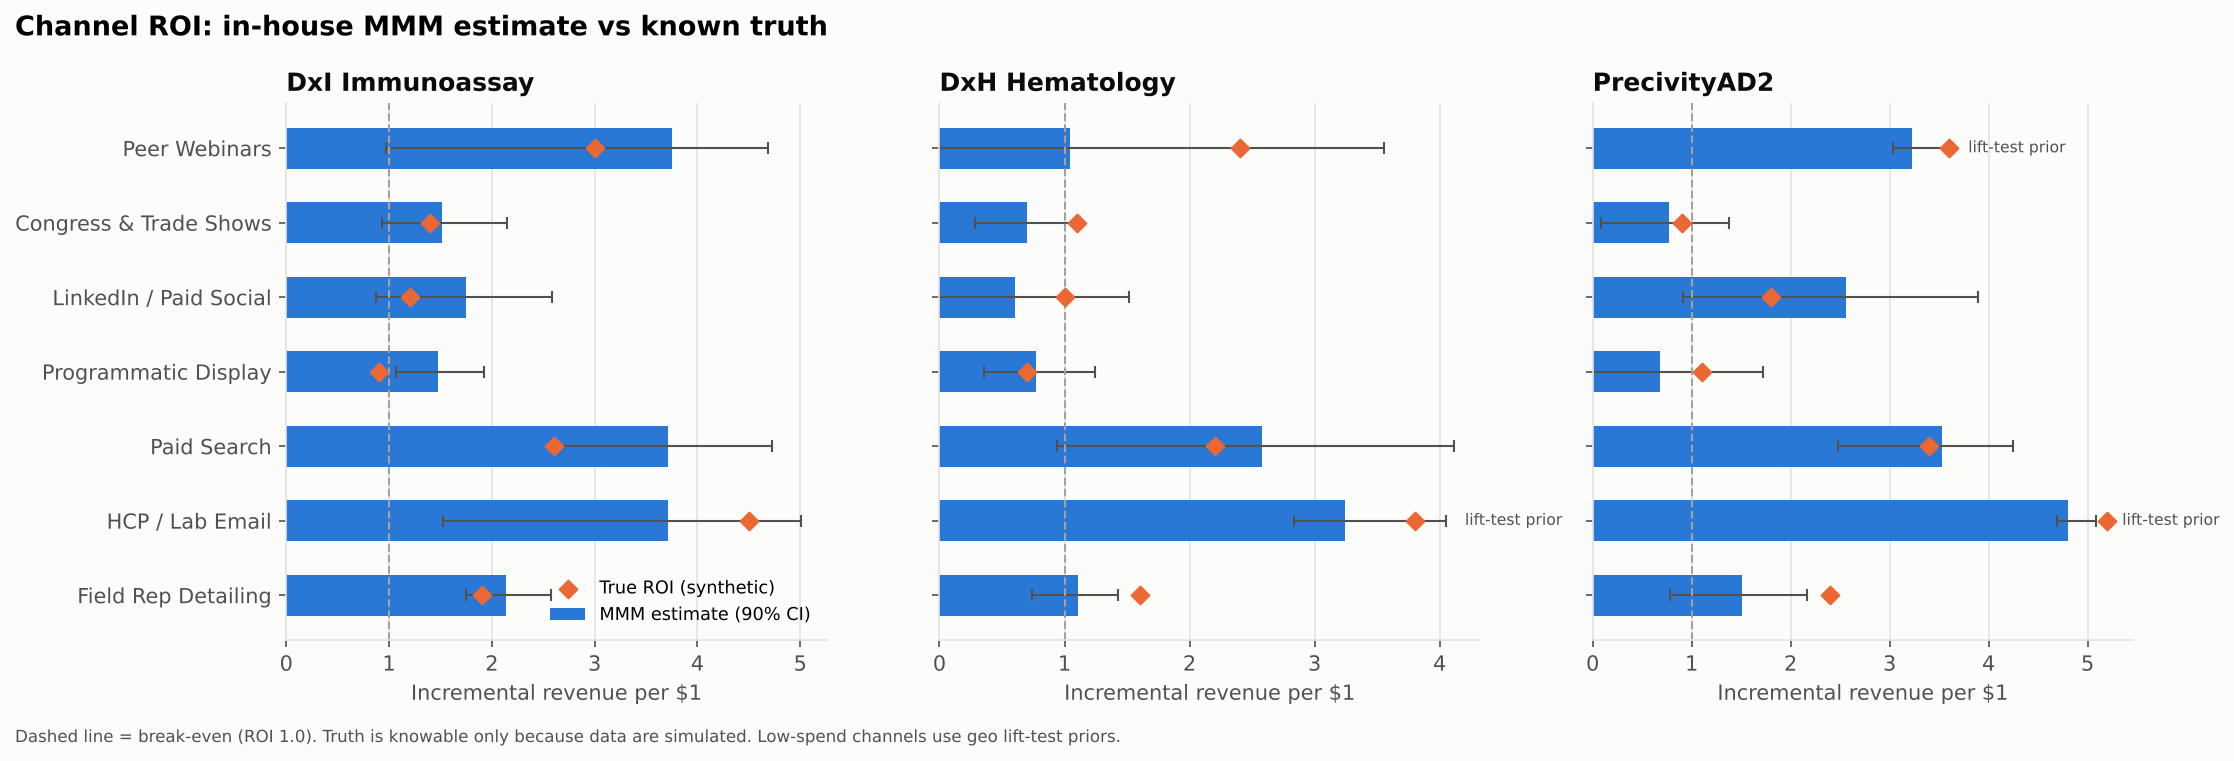

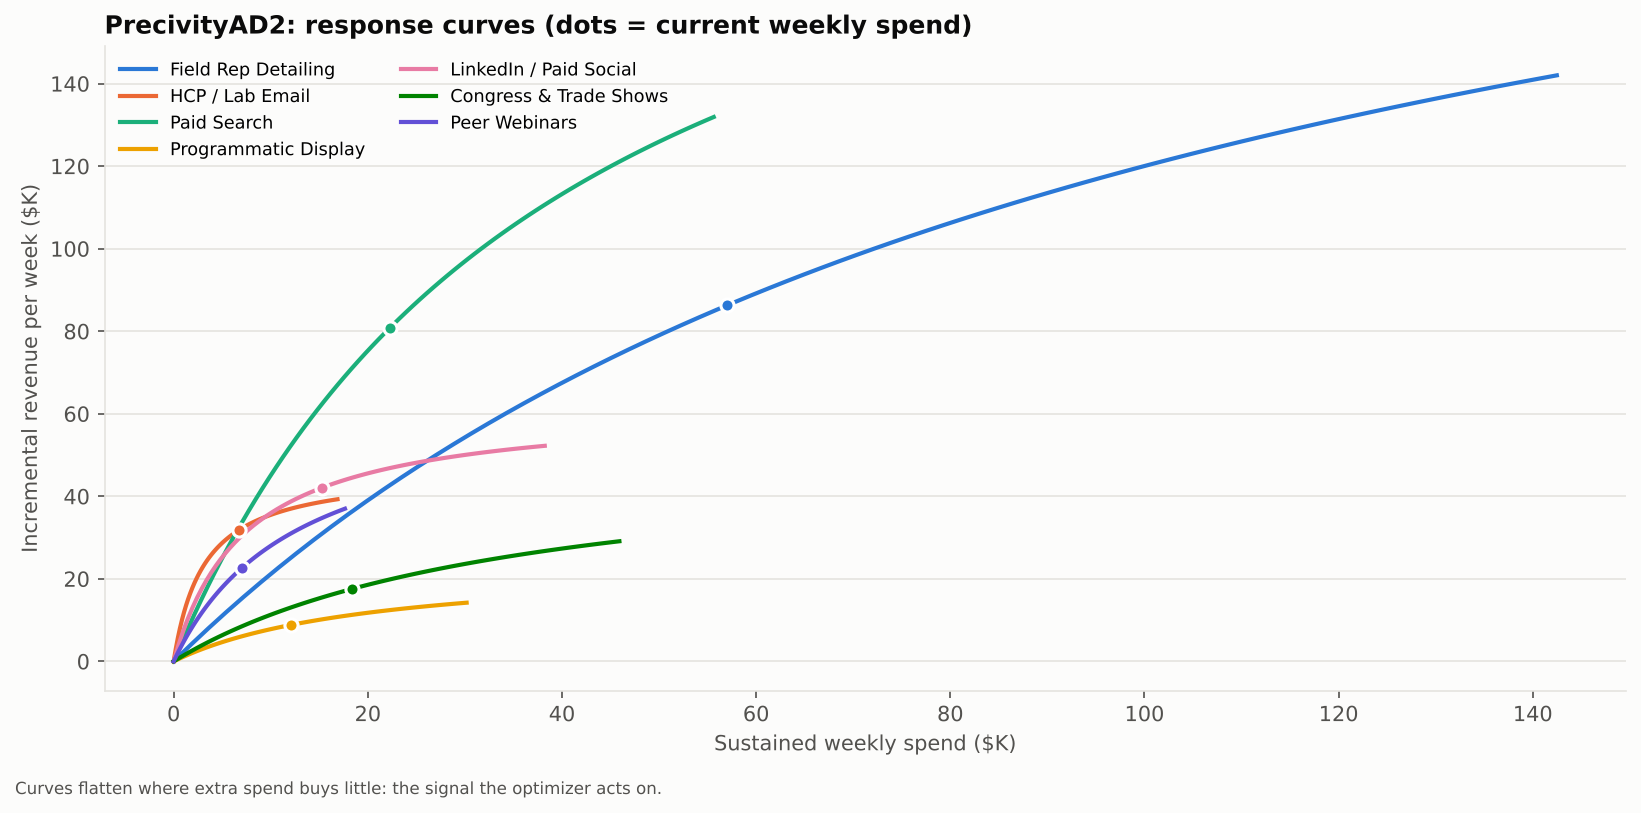

In [7]:
show('analytics/07_mmm_roi_vs_truth.png'); show('analytics/08_mmm_response_curves_c2n.png', 800)

## 3. Budget optimization (constant total spend)

In [8]:
o = S['C2N_AD2']['optimizer']
pd.DataFrame({'current $/wk': o['current'], 'optimal $/wk': o['optimal']}).assign(change=lambda d: d['optimal $/wk']/d['current $/wk']-1).round(2)

,current $/wk,optimal $/wk,change
REP,56991.94,54159.22,-0.05
EML,6750.60,8607.81,0.28
SRCH,22252.99,33379.49,0.50
DISP,12071.01,7242.61,-0.40
SOC,15290.82,13785.62,-0.10
CONF,18365.54,11019.32,-0.40
WEB,7057.66,10586.50,0.50


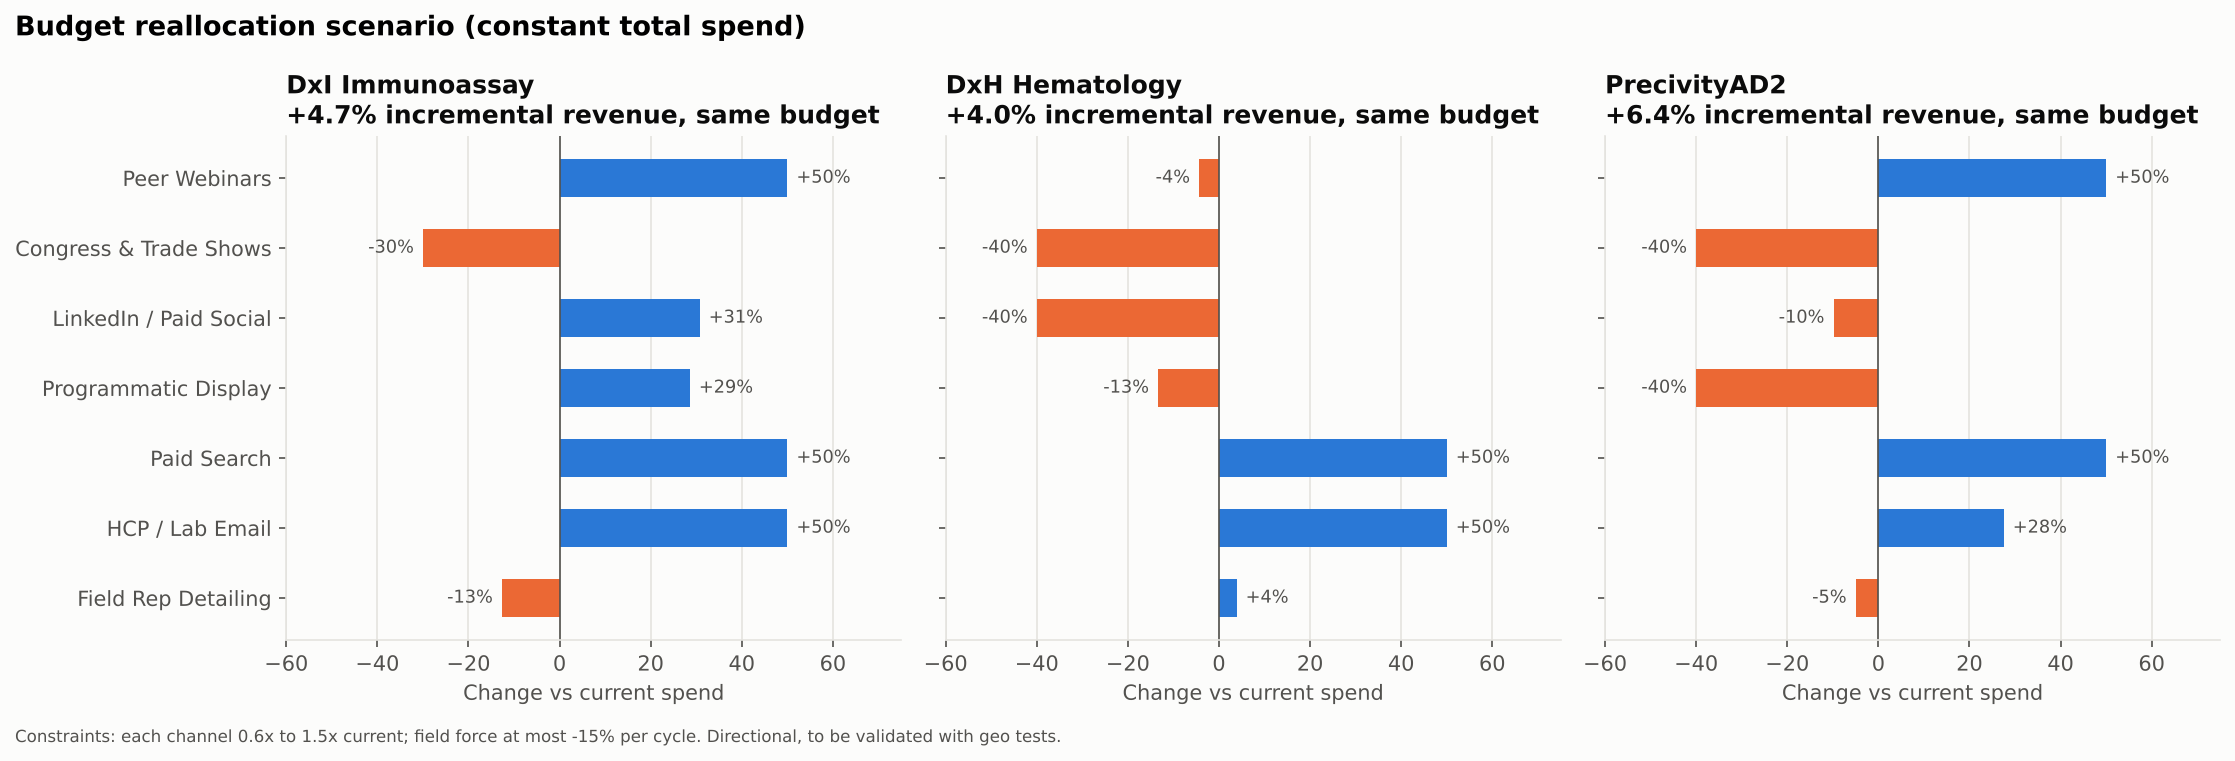

In [9]:
show('analytics/09_budget_reallocation.png')

## 4. Governed KPI scorecard

In [10]:
k = kpis.run(t, S['portfolio']['incremental_roi'])
k[['year_quarter','spend','orders','cpo','nps','csat_top2','fcr','resolution_hrs']].round(2)

[kpis] 12 quarters, catalog=12 KPIs


,year_quarter,spend,orders,cpo,nps,csat_top2,fcr,resolution_hrs
0,2023-Q1,4968013.71,62098,80.00,15.64,0.60,0.62,24.04
1,2023-Q2,5499160.65,67685,81.25,16.85,0.59,0.63,24.67
2,2023-Q3,6562163.96,67491,97.23,16.01,0.59,0.63,24.48
3,2023-Q4,5424377.11,64176,84.52,19.03,0.61,0.62,23.83
4,2024-Q1,5682795.33,67219,84.54,15.00,0.61,0.60,23.32
5,2024-Q2,6074084.77,73559,82.57,15.11,0.61,0.62,24.47
6,2024-Q3,6537997.94,77425,84.44,21.16,0.64,0.64,22.99
7,2024-Q4,5636052.40,68362,82.44,38.64,0.71,0.69,19.90
8,2025-Q1,6684821.36,73799,90.58,36.70,0.74,0.73,18.57
9,2025-Q2,6721592.36,78740,85.36,43.81,0.76,0.72,19.01


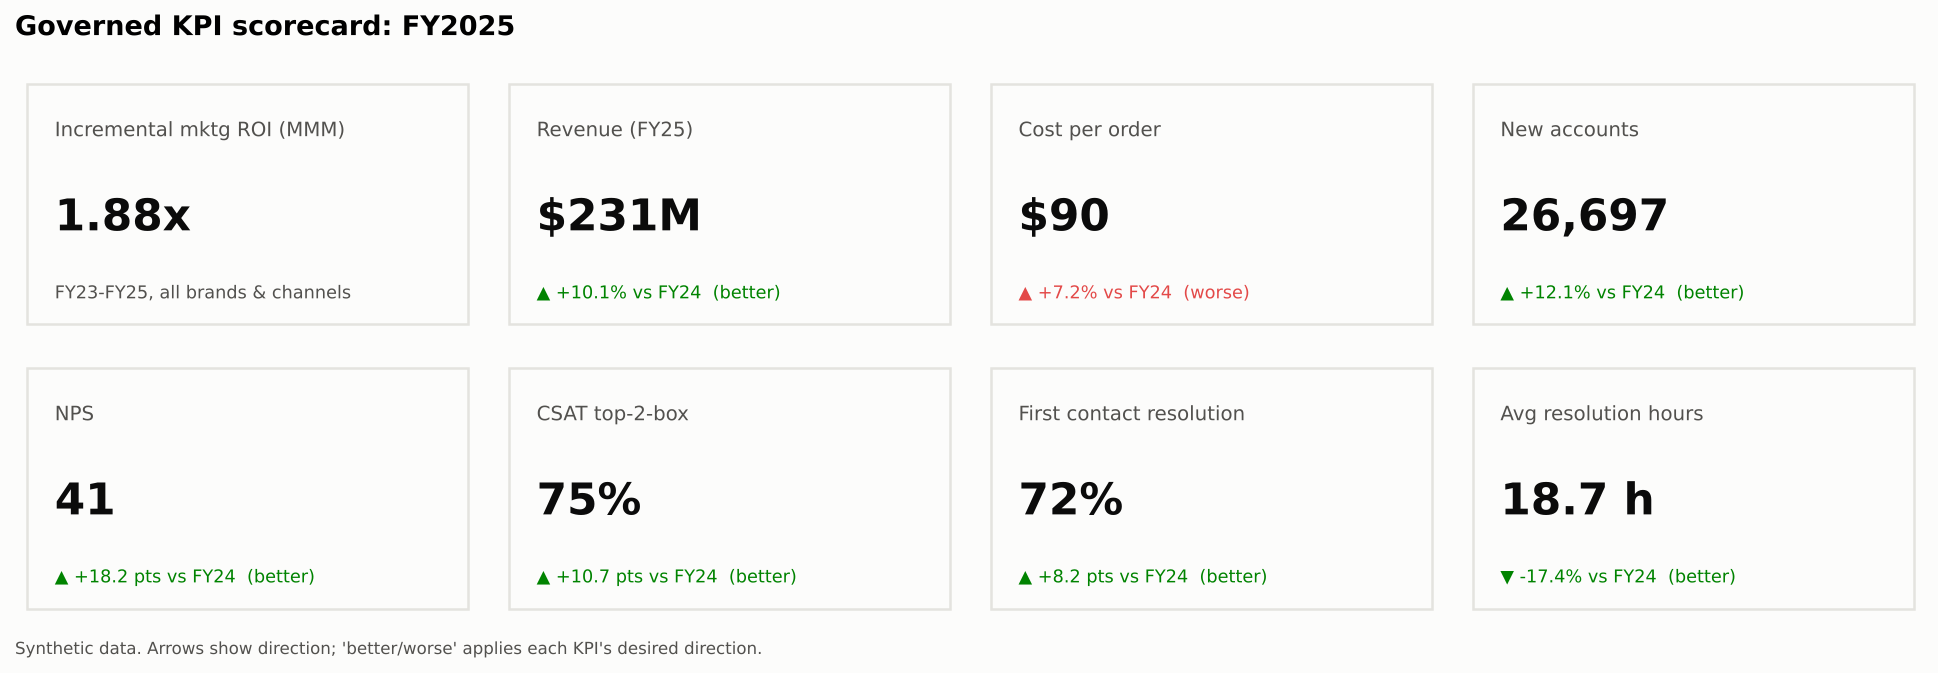

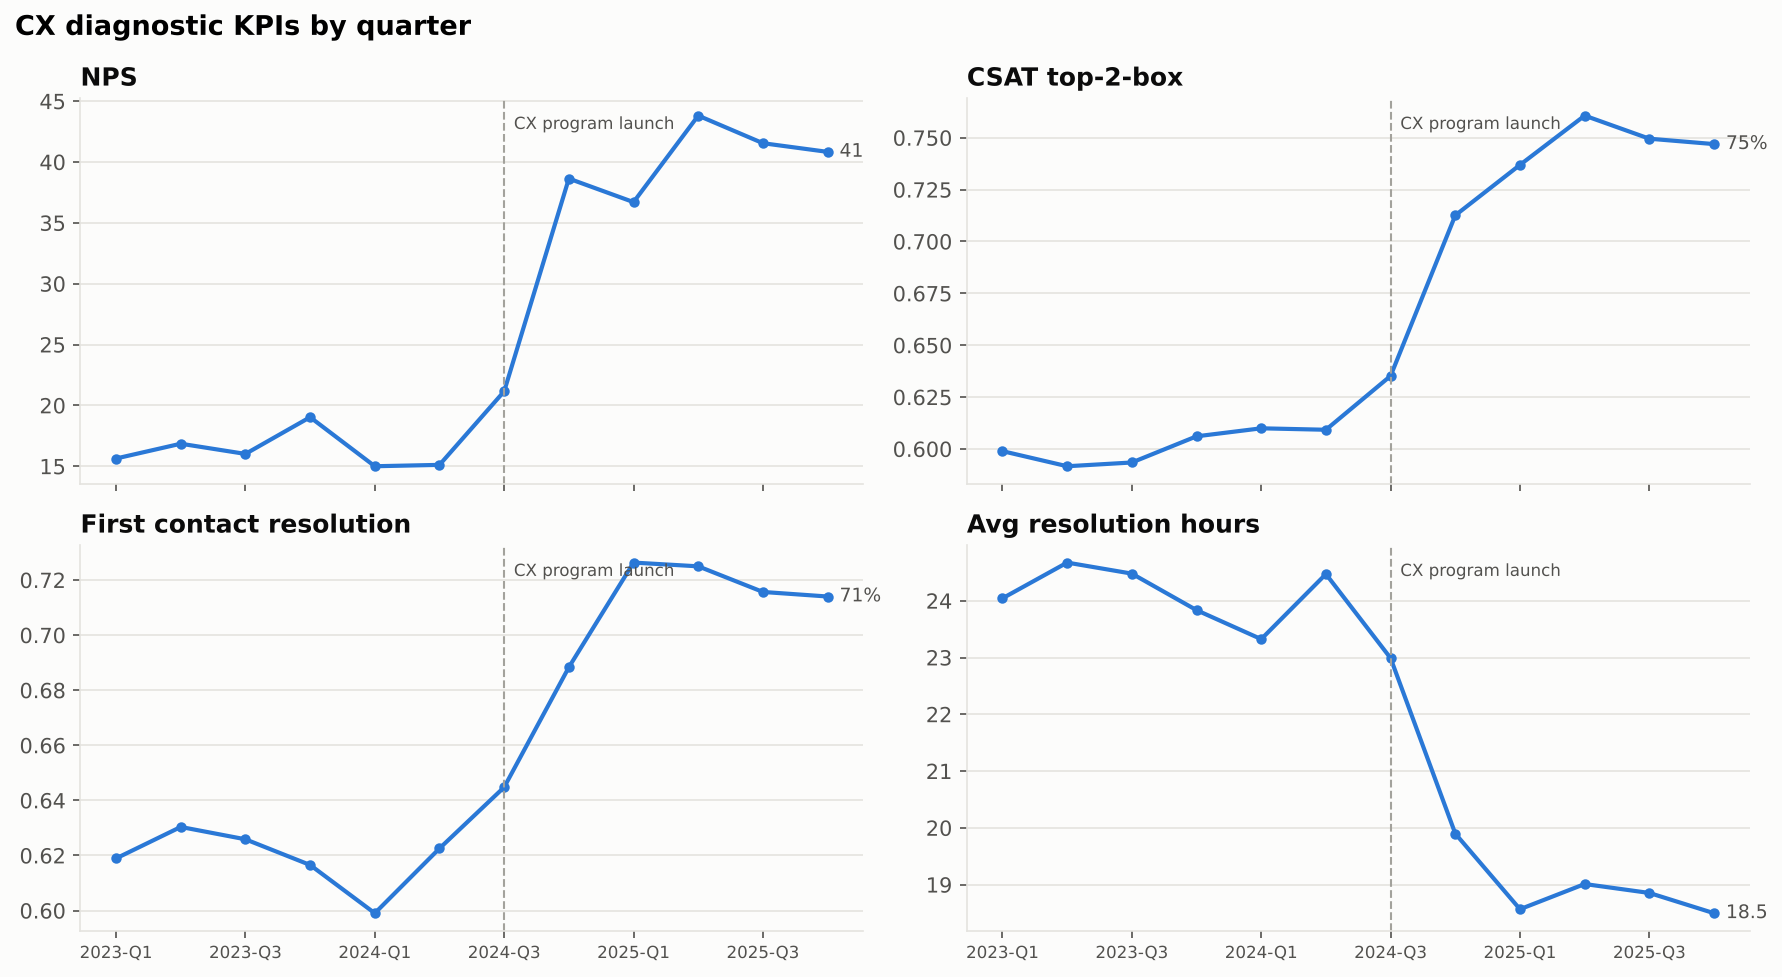

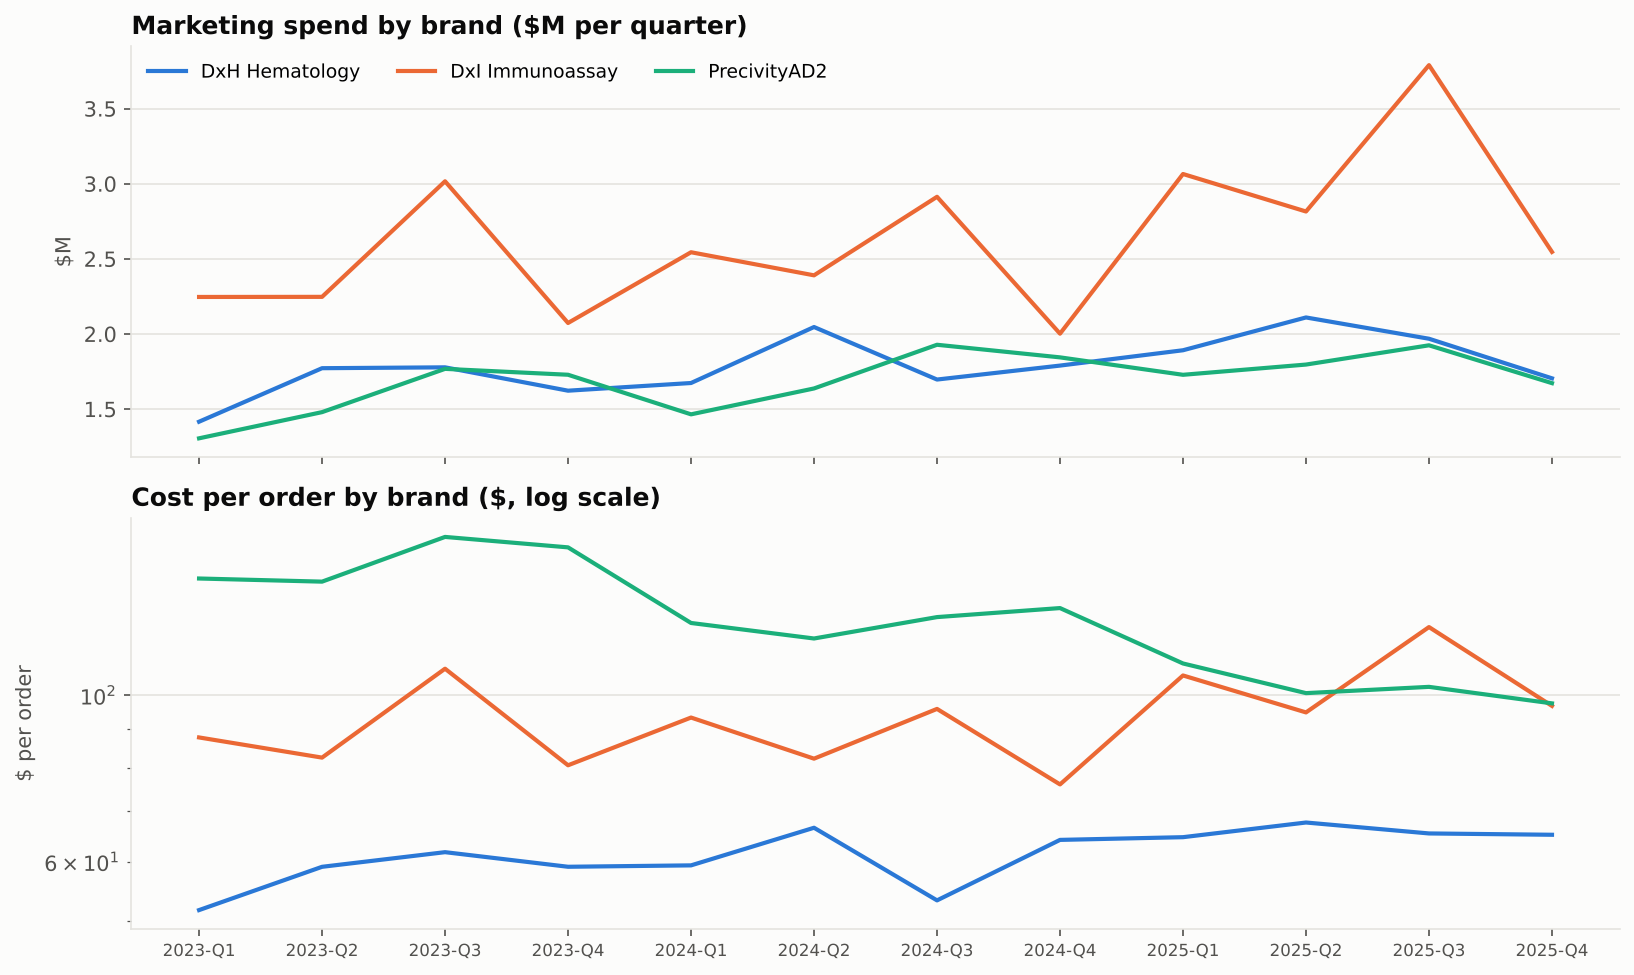

In [11]:
show('analytics/02_kpi_scorecard.png'); show('analytics/03_cx_kpi_trends.png'); show('analytics/04_brand_spend_cpo.png', 800)